**ACTIVIDAD 3: Taller EDA**

**1. Escoge un conjunto de datos de tu interés** ( https://www.kaggle.com/datasets)

Se escogió: Argentina Oil & Gas Production Dataset (2009–2025)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
archivos = files.upload()
nombre_archivo = next(iter(archivos))
df_original = pd.read_csv(nombre_archivo)
print("Archivo cargado:", nombre_archivo)
display(df_original.head())

Saving argentina_oil_gas_dataset_final.csv to argentina_oil_gas_dataset_final.csv
Archivo cargado: argentina_oil_gas_dataset_final.csv


,fecha,petroleo_convencional,petroleo_shale,petroleo_tight,petroleo_total,gas_convencional,gas_shale,gas_tight,gas_total,cuenca_neuquina,cuenca_gsj,cuenca_austral,cuenca_noroeste,cuenca_cuyana,petroleo_no_conv,gas_no_conv,pozos_no_conv_activos,precio_brent,metros_perforados,pozos_terminados
0,2009-01-01,3.029077e+06,1117.809,5374.4675,3.035570e+06,3.978842e+06,940.709,87738.5373,4.067521e+06,1.330268e+06,1.346993e+06,151053.8239,69166.0508,169891.9336,6492.276530,88679.24625,128,43.439500,239410.0,40.0
1,2009-02-01,2.795626e+06,978.129,4546.0238,2.801150e+06,3.635304e+06,668.866,83037.4831,3.719010e+06,1.205879e+06,1.270357e+06,139450.2367,62116.8302,152852.3260,5524.152814,83706.34909,131,43.324737,191175.0,36.0
2,2009-03-01,3.073065e+06,891.355,5258.2812,3.079215e+06,4.099806e+06,691.808,95699.5706,4.196197e+06,1.308424e+06,1.418671e+06,148742.1126,67851.8199,168684.0700,6149.636227,96391.37864,142,46.540455,224486.0,36.0
3,2009-04-01,2.961121e+06,790.847,4499.9704,2.966412e+06,3.975565e+06,670.323,88561.8091,4.064797e+06,1.274022e+06,1.350343e+06,149418.1445,61526.0906,161061.0502,5290.817414,89232.13212,139,50.181905,170589.0,32.0
4,2009-05-01,3.036101e+06,814.371,5796.6446,3.042712e+06,4.103666e+06,788.313,92153.0261,4.196607e+06,1.278665e+06,1.423012e+06,140437.9487,66874.5106,162202.6791,6611.015623,92941.33914,140,57.302500,166930.0,33.0


**2.1. Exploración de datos**

In [2]:
print("Cantidad de filas:", df_original.shape[0])
print("Cantidad de columnas:", df_original.shape[1])
print("\nColumnas:")
print(df_original.columns.tolist())
print("\nTipos y valores no nulos:")
df_original.info()
print("\nEstadísticas descriptivas:")
display(df_original.describe(include="all").T)
print("\nValores nulos por columna:")
display(df_original.isna().sum().to_frame("nulos"))
print("\nPorcentaje de valores nulos:")
display((df_original.isna().mean() * 100).round(2).to_frame("porcentaje_nulos"))
print("\nFilas completamente duplicadas:", df_original.duplicated().sum())

Cantidad de filas: 203
Cantidad de columnas: 20

Columnas:
['fecha', 'petroleo_convencional', 'petroleo_shale', 'petroleo_tight', 'petroleo_total', 'gas_convencional', 'gas_shale', 'gas_tight', 'gas_total', 'cuenca_neuquina', 'cuenca_gsj', 'cuenca_austral', 'cuenca_noroeste', 'cuenca_cuyana', 'petroleo_no_conv', 'gas_no_conv', 'pozos_no_conv_activos', 'precio_brent', 'metros_perforados', 'pozos_terminados']

Tipos y valores no nulos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 203 entries, 0 to 202
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   fecha                  203 non-null    object 
 1   petroleo_convencional  203 non-null    float64
 2   petroleo_shale         203 non-null    float64
 3   petroleo_tight         203 non-null    float64
 4   petroleo_total         203 non-null    float64
 5   gas_convencional       203 non-null    float64
 6   gas_shale              203 non-null 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
fecha,203,203,2009-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
petroleo_convencional,203.0,NaN,NaN,NaN,2148618.681723,494690.300392,1274685.7591,1659812.83025,2118508.7355,2547049.8522,3073065.4957
petroleo_shale,203.0,NaN,NaN,NaN,552685.831241,714062.0122,623.002,21568.6748,182107.8496,813027.4301,2801581.4618
petroleo_tight,203.0,NaN,NaN,NaN,22672.071641,12084.836389,3030.8727,12355.49665,24540.6407,30657.33245,46317.7649
petroleo_total,203.0,NaN,NaN,NaN,2723976.584604,398834.318042,2149474.2079,2451901.6506,2622991.5322,2879859.6584,4193526.3376
gas_convencional,203.0,NaN,NaN,NaN,2666862.706136,798035.671547,0.0,1915999.3006,2732903.157,3302140.48365,4199767.677
gas_shale,203.0,NaN,NaN,NaN,674493.486903,784922.466735,444.031,14102.0418,183536.9335,1237562.9647,2820251.111
gas_tight,203.0,NaN,NaN,NaN,499870.4098,262127.332708,71524.6556,207511.1662,562173.3619,729130.2354,902289.5028
gas_total,203.0,NaN,NaN,NaN,3841226.60284,380863.758411,872441.1043,3617334.748,3817714.8109,4022835.5544,4983609.4633
cuenca_neuquina,203.0,NaN,NaN,NaN,1378194.269619,515853.354381,890740.6379,1070914.82075,1149541.6545,1376759.1831,3222376.8602



Valores nulos por columna:


,nulos
fecha,0
petroleo_convencional,0
petroleo_shale,0
petroleo_tight,0
petroleo_total,0
gas_convencional,0
gas_shale,0
gas_tight,0
gas_total,0
cuenca_neuquina,0



Porcentaje de valores nulos:


,porcentaje_nulos
fecha,0.0
petroleo_convencional,0.0
petroleo_shale,0.0
petroleo_tight,0.0
petroleo_total,0.0
gas_convencional,0.0
gas_shale,0.0
gas_tight,0.0
gas_total,0.0
cuenca_neuquina,0.0



Filas completamente duplicadas: 0


**2.2. Limpieza de datos**

In [4]:
df = df_original.copy()
duplicados_antes = df.duplicated().sum()
df = df.drop_duplicates()
df["fecha"] = pd.to_datetime(df["fecha"], errors="coerce")
columnas_no_fecha = [c for c in df.columns if c != "fecha"]
for col in columnas_no_fecha:
    df[col] = pd.to_numeric(df[col], errors="coerce")
filas_antes = len(df)
df = df.dropna(subset=["fecha", "petroleo_total"]).copy()
print("Duplicados eliminados:", duplicados_antes)
print("Registros descartados por fecha/producción faltante:", filas_antes - len(df))
print("Dimensiones después de limpiar:", df.shape)
print("Nulos restantes:", int(df.isna().sum().sum()))
display(df.head())

Duplicados eliminados: 0
Registros descartados por fecha/producción faltante: 0
Dimensiones después de limpiar: (203, 20)
Nulos restantes: 0


,fecha,petroleo_convencional,petroleo_shale,petroleo_tight,petroleo_total,gas_convencional,gas_shale,gas_tight,gas_total,cuenca_neuquina,cuenca_gsj,cuenca_austral,cuenca_noroeste,cuenca_cuyana,petroleo_no_conv,gas_no_conv,pozos_no_conv_activos,precio_brent,metros_perforados,pozos_terminados
0,2009-01-01,3.029077e+06,1117.809,5374.4675,3.035570e+06,3.978842e+06,940.709,87738.5373,4.067521e+06,1.330268e+06,1.346993e+06,151053.8239,69166.0508,169891.9336,6492.276530,88679.24625,128,43.439500,239410.0,40.0
1,2009-02-01,2.795626e+06,978.129,4546.0238,2.801150e+06,3.635304e+06,668.866,83037.4831,3.719010e+06,1.205879e+06,1.270357e+06,139450.2367,62116.8302,152852.3260,5524.152814,83706.34909,131,43.324737,191175.0,36.0
2,2009-03-01,3.073065e+06,891.355,5258.2812,3.079215e+06,4.099806e+06,691.808,95699.5706,4.196197e+06,1.308424e+06,1.418671e+06,148742.1126,67851.8199,168684.0700,6149.636227,96391.37864,142,46.540455,224486.0,36.0
3,2009-04-01,2.961121e+06,790.847,4499.9704,2.966412e+06,3.975565e+06,670.323,88561.8091,4.064797e+06,1.274022e+06,1.350343e+06,149418.1445,61526.0906,161061.0502,5290.817414,89232.13212,139,50.181905,170589.0,32.0
4,2009-05-01,3.036101e+06,814.371,5796.6446,3.042712e+06,4.103666e+06,788.313,92153.0261,4.196607e+06,1.278665e+06,1.423012e+06,140437.9487,66874.5106,162202.6791,6611.015623,92941.33914,140,57.302500,166930.0,33.0


**2.3. Filtrado, selección de datos y creación de variables**

In [5]:
df["anio"] = df["fecha"].dt.year
df["mes"] = df["fecha"].dt.month
df["decada"] = (df["anio"] // 10) * 10
df["porcentaje_shale"] = np.where(
    df["petroleo_total"] > 0,
    df["petroleo_shale"] / df["petroleo_total"] * 100,
    np.nan)
df["porcentaje_no_convencional"] = np.where(
    df["petroleo_total"] > 0,
    df["petroleo_no_conv"] / df["petroleo_total"] * 100,
    np.nan)
print("Periodo:", df["fecha"].min().date(), "a", df["fecha"].max().date())
display(df[["fecha", "anio", "mes", "decada", "petroleo_total",
            "petroleo_shale", "porcentaje_shale"]].head())

Periodo: 2009-01-01 a 2025-11-01


,fecha,anio,mes,decada,petroleo_total,petroleo_shale,porcentaje_shale
0,2009-01-01,2009,1,2000,3.035570e+06,1117.809,0.036824
1,2009-02-01,2009,2,2000,2.801150e+06,978.129,0.034919
2,2009-03-01,2009,3,2000,3.079215e+06,891.355,0.028947
3,2009-04-01,2009,4,2000,2.966412e+06,790.847,0.026660
4,2009-05-01,2009,5,2000,3.042712e+06,814.371,0.026765


**2.4. Agrupación y resumenes**

In [6]:
resumen_anual = df.groupby("anio").agg(
    petroleo_promedio=("petroleo_total", "mean"),
    gas_promedio=("gas_total", "mean"),
    brent_promedio=("precio_brent", "mean"),
    pozos_activos_promedio=("pozos_no_conv_activos", "mean"),
    porcentaje_shale_promedio=("porcentaje_shale", "mean"),
    meses_registrados=("fecha", "count")).round(2)
display(resumen_anual)
resumen_decada = df.groupby("decada").agg(
    petroleo_promedio=("petroleo_total", "mean"),
    shale_promedio=("petroleo_shale", "mean"),
    convencional_promedio=("petroleo_convencional", "mean"),
    pozos_activos_promedio=("pozos_no_conv_activos", "mean"),
    registros=("fecha", "count")).round(2)
display(resumen_decada)

,petroleo_promedio,gas_promedio,brent_promedio,pozos_activos_promedio,porcentaje_shale_promedio,meses_registrados
anio,,,,,,
2009,2919321.50,4034877.99,61.49,141.50,0.03,12
2010,2849936.49,3925631.98,79.51,169.83,0.04,12
2011,2676322.99,3793962.76,111.26,216.58,0.19,12
2012,2664050.04,3676974.47,111.62,303.33,0.51,12
2013,2611077.98,3475691.01,108.64,432.00,1.25,12
2014,2573306.31,3457002.10,99.02,731.42,3.12,12
2015,2574801.47,3575461.05,52.35,1070.08,4.29,12
2016,2475772.80,3748994.65,43.55,1435.42,5.84,12
2017,2319677.15,3721415.83,54.25,1727.83,7.82,12


,petroleo_promedio,shale_promedio,convencional_promedio,pozos_activos_promedio,registros
decada,,,,,
2000,2919321.50,814.78,2913813.12,141.50,12
2010,2557240.73,128511.86,2407405.06,1057.08,120
2020,2972767.62,1362873.57,1581904.62,3466.32,71


Se obtienen promedios anuales y por década para resumir la evolución histórica.

**3. Preguntas**



*   ¿Cómo evolucionó la producción total de petróleo a lo largo del periodo?
*   ¿Cómo cambió la participación del petróleo shale frente al petróleo convencional?
*   ¿Qué cuencas registran la mayor producción promedio de petróleo?
*   ¿Qué relación se observa entre el precio Brent y la producción total de petróleo?
*   ¿Cómo cambió la cantidad de pozos no convencionales activos?








**4. Respuestas**

**¿Cómo evolucionó la producción total de petróleo a lo largo del periodo?**

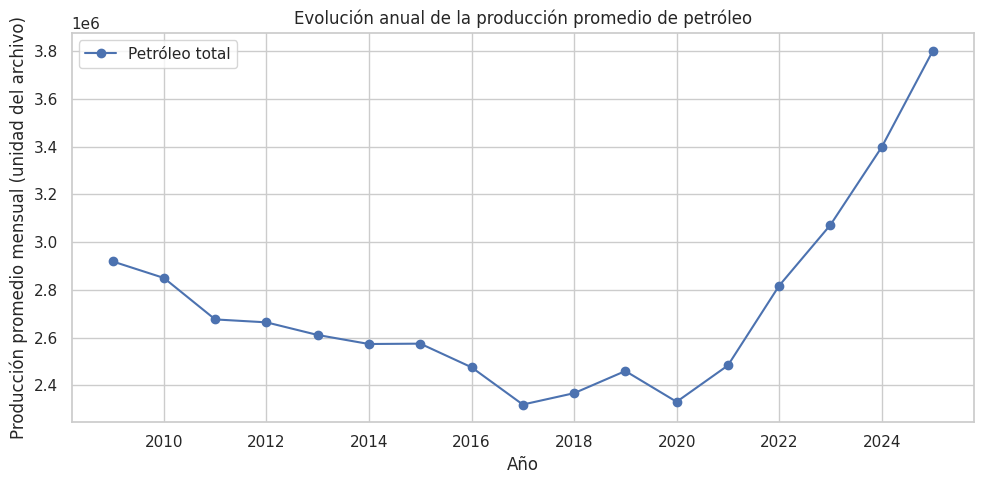

Primer valor disponible: 3035569.5729
Último valor disponible: 4046326.7493
Cambio porcentual entre primer y último registro: 33.3 %


In [7]:
petroleo_anual = df.groupby("anio")["petroleo_total"].mean()
ax = petroleo_anual.plot(marker="o")
ax.set_title("Evolución anual de la producción promedio de petróleo")
ax.set_xlabel("Año")
ax.set_ylabel("Producción promedio mensual (unidad del archivo)")
ax.legend(["Petróleo total"])
plt.tight_layout()
plt.show()
print("Primer valor disponible:", df.iloc[0]["petroleo_total"])
print("Último valor disponible:", df.iloc[-1]["petroleo_total"])
print("Cambio porcentual entre primer y último registro:",
      round((df.iloc[-1]["petroleo_total"] / df.iloc[0]["petroleo_total"] - 1) * 100, 2), "%")

La gráfica muestra que la producción promedio de petróleo en Argentina presentó una tendencia descendente entre 2009 y 2017, pasando de aproximadamente 2,9 a 2,3 millones de unidades. A partir de 2020, la producción comenzó a recuperarse, con un crecimiento notable desde 2021 hasta alcanzar cerca de 3,8 millones en 2025. En general, se observa una recuperación importante de la producción petrolera en los últimos años, con un aumento del 33,3 % entre el primer y el último registro del conjunto de datos.

**¿Cómo cambió la participación del petróleo shale frente al petróleo convencional?**

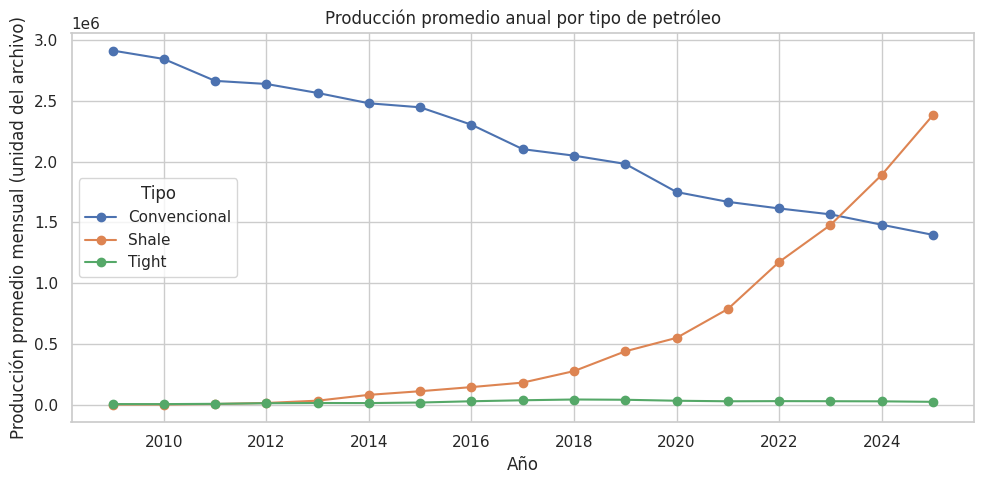

,fecha,petroleo_convencional,petroleo_shale,petroleo_tight,petroleo_total,porcentaje_shale
0,2009-01-01,3.029077e+06,1.117809e+03,5374.4675,3.035570e+06,0.036824
201,2025-10-01,1.371412e+06,2.801581e+06,20533.2519,4.193526e+06,66.807294


In [8]:
tipos_anuales = df.groupby("anio")[[
    "petroleo_convencional", "petroleo_shale", "petroleo_tight"]].mean()
ax = tipos_anuales.plot(marker="o")
ax.set_title("Producción promedio anual por tipo de petróleo")
ax.set_xlabel("Año")
ax.set_ylabel("Producción promedio mensual (unidad del archivo)")
ax.legend(["Convencional", "Shale", "Tight"], title="Tipo")
plt.tight_layout()
plt.show()
display(df.loc[df["fecha"].isin(pd.to_datetime(["2009-01-01", "2025-10-01"])),
               ["fecha", "petroleo_convencional", "petroleo_shale",
                "petroleo_tight", "petroleo_total", "porcentaje_shale"]])

La gráfica muestra que la producción de petróleo convencional presentó una disminución progresiva, pasando de aproximadamente 2,9 millones de unidades en 2009 a 1,4 millones en 2025. Por el contrario, la producción de petróleo shale aumentó considerablemente, especialmente desde 2020, hasta superar la producción convencional en 2024. El petróleo tight mantuvo una participación mucho menor durante todo el periodo. Estos resultados evidencian un cambio importante en la estructura de la producción petrolera argentina, donde el shale ha adquirido un papel cada vez más relevante.

**¿Qué cuencas registran la mayor producción promedio de petróleo?**

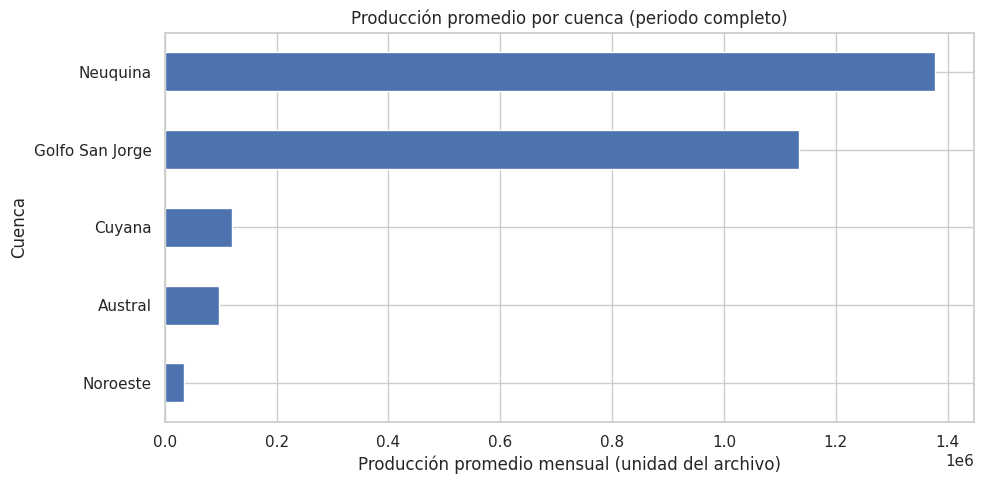

,promedio
cuenca_neuquina,1.378194e+06
cuenca_gsj,1.134031e+06
cuenca_cuyana,1.208033e+05
cuenca_austral,9.731988e+04
cuenca_noroeste,3.456907e+04


In [9]:
columnas_cuencas = ["cuenca_neuquina", "cuenca_gsj", "cuenca_austral", "cuenca_noroeste", "cuenca_cuyana"]
promedio_cuencas = df[columnas_cuencas].mean().sort_values(ascending=True)
ax = promedio_cuencas.plot(kind="barh")
ax.set_title("Producción promedio por cuenca (periodo completo)")
ax.set_xlabel("Producción promedio mensual (unidad del archivo)")
ax.set_ylabel("Cuenca")
ax.set_yticklabels([ "Cuyana" if x == "cuenca_cuyana" else "Noroeste" if x == "cuenca_noroeste" else  "Austral" if x == "cuenca_austral" else "Golfo San Jorge" if x == "cuenca_gsj" else  "Neuquina" for x in promedio_cuencas.index ])
plt.tight_layout()
plt.show()
display(promedio_cuencas.sort_values(ascending=False).to_frame("promedio"))

La gráfica muestra que la cuenca Neuquina presenta la mayor producción promedio mensual de petróleo, con aproximadamente 1,38 millones de unidades, seguida por la cuenca del Golfo San Jorge, con cerca de 1,13 millones. En contraste, las cuencas Cuyana, Austral y Noroeste registran niveles considerablemente menores. Estos resultados evidencian que la producción petrolera argentina está concentrada principalmente en las cuencas Neuquina y Golfo San Jorge, por lo que su desempeño tiene una gran importancia para la producción nacional.

**¿Qué relación se observa entre el precio Brent y la producción total de petróleo?**

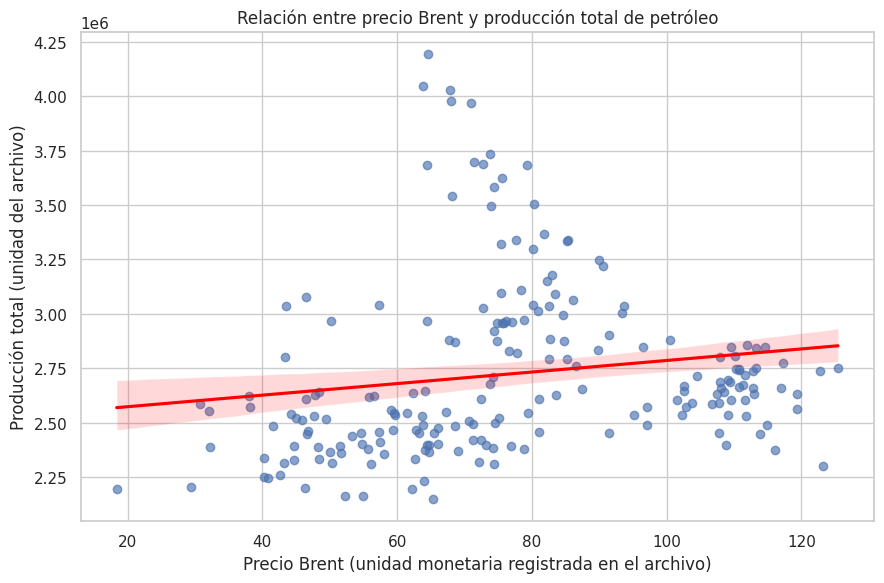

Correlación de Pearson: 0.159


In [10]:
datos_relacion = df[["precio_brent", "petroleo_total"]].dropna()
plt.figure(figsize=(9, 6))
sns.regplot( data=datos_relacion, x="precio_brent", y="petroleo_total", scatter_kws={"alpha": 0.65}, line_kws={"color": "red"})
plt.title("Relación entre precio Brent y producción total de petróleo")
plt.xlabel("Precio Brent (unidad monetaria registrada en el archivo)")
plt.ylabel("Producción total (unidad del archivo)")
plt.tight_layout()
plt.show()
correlacion = datos_relacion["precio_brent"].corr(datos_relacion["petroleo_total"])
print("Correlación de Pearson:", round(correlacion, 3))

La gráfica muestra una relación positiva débil entre el precio internacional del petróleo Brent y la producción total de petróleo de Argentina, con un coeficiente de correlación de Pearson de 0,159. Esto significa que, aunque la producción tiende a aumentar ligeramente cuando el precio Brent sube, la relación entre ambas variables es poco significativa. Por lo tanto, el precio internacional no explica por sí solo las variaciones en la producción, ya que también pueden influir factores como la inversión, la tecnología, la capacidad de extracción y el desarrollo de yacimientos no convencionales.

**¿Cómo cambió la cantidad de pozos no convencionales activos?**

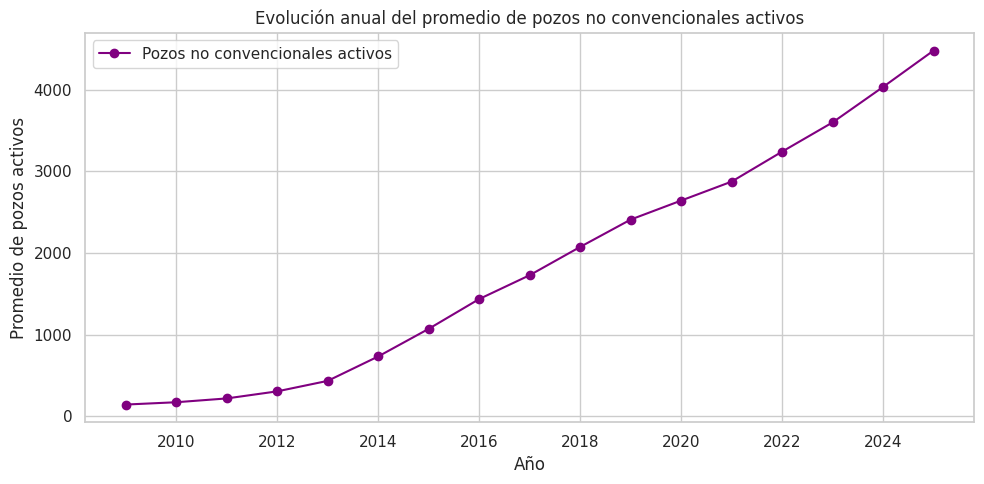

Primer registro: 128
Último registro: 4703


In [11]:
pozos_anuales = df.groupby("anio")["pozos_no_conv_activos"].mean()
ax = pozos_anuales.plot(marker="o", color="purple")
ax.set_title("Evolución anual del promedio de pozos no convencionales activos")
ax.set_xlabel("Año")
ax.set_ylabel("Promedio de pozos activos")
ax.legend(["Pozos no convencionales activos"])
plt.tight_layout()
plt.show()
print("Primer registro:", int(df.iloc[0]["pozos_no_conv_activos"]))
print("Último registro:", int(df.iloc[-1]["pozos_no_conv_activos"]))

La gráfica muestra un crecimiento sostenido en la cantidad promedio de pozos no convencionales activos en Argentina entre 2009 y 2025. Al inicio del periodo se registraban 128 pozos, mientras que en el último registro la cifra alcanzó los 4.703. Este incremento evidencia una expansión importante de la actividad de extracción no convencional, especialmente durante los últimos años. Además, esta tendencia coincide con el aumento de la producción de petróleo shale, lo que sugiere que el desarrollo de nuevos pozos ha acompañado el crecimiento de este tipo de producción en el país.

5. Conclusiones


*   El primer registro mensual de petróleo total es de aproximadamente 3,04 millones y el último de 4,05 millones en las unidades registradas, una diferencia cercana al 33,3 %. La comparación indica un nivel mayor al final del periodo, aunque la trayectoria debe interpretarse con la gráfica anual porque puede incluir caídas y recuperaciones.
*   La participación del shale pasa de cerca de 0,04 % en enero de 2009 a alrededor de 66,8 % en octubre de 2025. Esto representa un cambio importante hacia la producción no convencional y sugiere que el shale se convirtió en un componente central de la producción petrolera registrada.
*   La cuenca Neuquina presenta el mayor promedio entre las cuencas incluidas, seguida por Golfo San Jorge. Además, los pozos no convencionales activos aumentan de 128 al inicio del periodo a 4.703 en el último registro. En conjunto, estos patrones son consistentes con la importancia creciente de la actividad no convencional y de la cuenca Neuquina, aunque no demuestran causalidad por sí solos.
*   El diagrama de dispersión y el coeficiente de Pearson permiten identificar si existe una asociación lineal entre precio internacional y producción en los registros disponibles. La correlación debe interpretarse como asociación, no como prueba de que el precio cause los cambios productivos.